# friday-mini walkthrough
A guided tour of how a language model works. Every code cell calls the *real* code in `src/`, so you can open that file and read the
same math line by line. Run the cells top to bottom.

**The big idea:** an LLM only ever does ONE thing: *given the words so far, guess the next word.* Chat = repeating that guess again and again.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..')); os.chdir('..')    # so we can import from src/
import torch
from src.utils.config import load_config
cfg = load_config('configs/model_config.yaml')
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none')
print(cfg)

GPU: NVIDIA GeForce GTX 1650 Ti
{'vocab_size': 8000, 'dim': 384, 'num_layers': 8, 'num_heads': 6, 'ffn_dim': 1024, 'context_length': 512, 'rope_theta': 10000.0, 'norm_eps': 1e-05, 'batch_size': 8, 'grad_accum': 4, 'pretrain_lr': 0.0006, 'sft_lr': 0.0002, 'min_lr_ratio': 0.1, 'warmup_steps': 200, 'weight_decay': 0.1, 'grad_clip': 1.0, 'pretrain_epochs': 6, 'sft_epochs': 4, 'eval_every': 250, 'save_every': 500}


## 1. How learning works (one neuron)
A model is just numbers (*weights*). Learning = nudge the numbers so the error shrinks. Here is the smallest possible example:
find `w` so that `w * 3 = 12`. We do the calculus by hand, then check PyTorch's automatic version (*autograd*) agrees.

In [2]:
w, x, target, lr = 0.5, 3.0, 12.0, 0.02
for step in range(8):
    pred = w * x                       # forward pass: make a guess
    loss = (pred - target) ** 2        # how wrong are we?
    grad = 2 * (pred - target) * x     # calculus by hand: d(loss)/d(w)
    w = w - lr * grad                  # nudge w downhill  (this is "gradient descent")
    print(f'step {step}: w={w:.3f} loss={loss:.3f}')

# same thing with autograd:
w2 = torch.tensor(0.5, requires_grad=True)
((w2 * x - target) ** 2).backward()
print('hand gradient:', 2 * (0.5 * x - target) * x, '| autograd gradient:', w2.grad.item())

step 0: w=1.760 loss=110.250
step 1: w=2.566 loss=45.158
step 2: w=3.082 loss=18.497
step 3: w=3.413 loss=7.576
step 4: w=3.624 loss=3.103
step 5: w=3.759 loss=1.271
step 6: w=3.846 loss=0.521
step 7: w=3.901 loss=0.213
hand gradient: -63.0 | autograd gradient: -63.0


## 2. Tokenizer: text -> numbers
Computers need numbers. We chop text into pieces (*tokens*) learned from our data (BPE). First the 40-line toy version, so you can see merging:

In [3]:
from src.tokenization.bpe_toy import train_bpe, encode_word
merges = train_bpe('iron man iron man avengers avengers avengers assemble thor thor hammer', 12)
print(merges)
print(encode_word('avengers', merges))

[('e', 'r'), ('a', 'v'), ('av', 'e'), ('ave', 'n'), ('aven', 'g'), ('aveng', 'er'), ('avenger', 's'), ('i', 'r'), ('ir', 'o'), ('iro', 'n'), ('m', 'a'), ('ma', 'n')]
['avengers']


Now the real tokenizer (needs `python -m src.tokenization.train_tokenizer` to have run):

In [4]:
from src.tokenization.tokenizer import Tok
tok = Tok()
ids = tok.encode('Thor wields Mjolnir.')
print(ids); print([tok.sp.id_to_piece(i) for i in ids]); print(tok.decode(ids))

[3434, 280, 5687, 2974, 7930]
['Thor', '▁w', 'ields', '▁Mjolnir', '.']
Thor wields Mjolnir.


## 3. Softmax and attention (the heart of a transformer)
*Softmax* turns any scores into probabilities. *Attention* uses it so each word can decide which earlier words matter.

In [5]:
from src.core.functional import softmax
scores = torch.tensor([2.0, 1.0, 0.1])
print(softmax(scores), softmax(scores).sum())

tensor([0.6590, 0.2424, 0.0986]) tensor(1.0000)


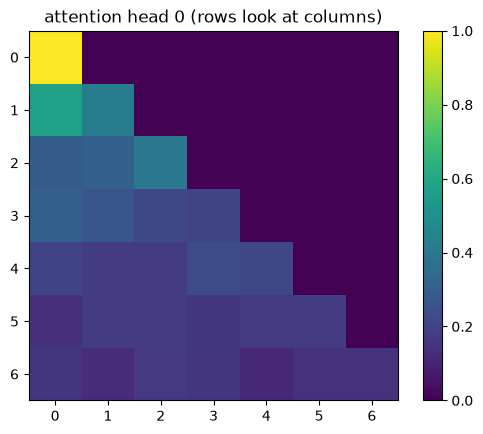

upper-right is empty (black): tokens cannot see the future.


In [6]:
# A real attention map: untrained model, 6 tokens. Row i shows how much token i looks at each earlier token.
from src.models.friday import Friday
from src.core.layers import rope_cos_sin, apply_rope
import math, matplotlib.pyplot as plt
model = Friday(cfg).eval()
ids = torch.tensor([tok.prompt_ids('Who is Thor?')])
att = model.model.layers[0].self_attn
with torch.no_grad():
    x = model.model.layers[0].input_layernorm(model.model.embed_tokens(ids))
    B, T, C_ = x.shape
    q = att.q_proj(x).view(B, T, att.h, att.d).transpose(1, 2); k = att.k_proj(x).view(B, T, att.h, att.d).transpose(1, 2)
    cos, sin = rope_cos_sin(T, att.d, cfg['rope_theta'])
    q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
    s = (q @ k.transpose(-2, -1)) / math.sqrt(att.d)
    s = s.masked_fill(torch.triu(torch.ones(T, T, dtype=torch.bool), 1), float('-inf'))
    w = softmax(s, -1)[0, 0]
plt.imshow(w, cmap='viridis'); plt.title('attention head 0 (rows look at columns)'); plt.colorbar(); plt.show()
print('upper-right is empty (black): tokens cannot see the future.')

## 4. The full model and its size
`src/models/friday.py`: embeddings -> 8 blocks of (attention + MLP) -> logits. Count the numbers inside:

In [7]:
print(f'friday parameters: {model.num_params()/1e6:.2f} million')
logits = model(ids)
print('input ids', tuple(ids.shape), '-> logits', tuple(logits.shape), '(one score per vocab word, per position)')

friday parameters: 17.23 million
input ids (1, 7) -> logits (1, 7, 8000) (one score per vocab word, per position)


## 5. Loss: how wrong is the guess?
An untrained model guesses randomly, so its loss should be about `ln(vocab_size)` = ln(8000) = 8.99.

In [8]:
from src.core.functional import cross_entropy
x, y = ids[:, :-1], ids[:, 1:]
print('loss:', cross_entropy(model(x).reshape(-1, cfg['vocab_size']), y.reshape(-1)).item(), '| random guess =', math.log(cfg['vocab_size']))

loss: 8.776856422424316 | random guess = 8.987196820661973


## 6. Train a few steps and watch the loss fall
(The real training is `python -m src.training.train`; this is the same loop in miniature, memorising one sentence.)

In [9]:
from src.training.optim import AdamW
m = Friday(cfg); opt = AdamW(m.parameters(), lr=1e-3, weight_decay=0.0)
x, y = ids[:, :-1], ids[:, 1:]
for step in range(40):
    loss = cross_entropy(m(x).reshape(-1, cfg['vocab_size']), y.reshape(-1))
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 8 == 0: print(step, round(loss.item(), 3))

0 9.075


8 1.846


16 0.134


24 0.024


32 0.008


## 7. Talk to the trained model
Needs `checkpoints/sft_best.pt` (after training). Temperature = creativity dial.

In [10]:
from src.inference.generate import generate
path = 'checkpoints/sft_best.pt'
if os.path.exists(path):
    ck = torch.load(path, map_location='cuda'); net = Friday(ck['config']).cuda(); net.load_state_dict(ck['model'])
    for q in ['Who is Thor?', 'Who plays Doctor Doom in Avengers: Doomsday?', 'What is the capital of France?']:
        out = generate(net, tok.prompt_ids(q), temperature=0.7, ctx=cfg['context_length'], eos_id=tok.eos)
        print('Q:', q, '\nA:', tok.decode(out), '\n')
else:
    print('Train first (see PLAN.md).')

Train first (see PLAN.md).
